# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the RSD46 WHU dataset.

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import RSD46WHUDataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/RSD46-WHU/train/",
    "csv_file": "./data/RSD46-WHU/rsd46whu_train.csv"
    }
dataset = RSD46WHUDataset(dataset_config)

## Show images from the dataset

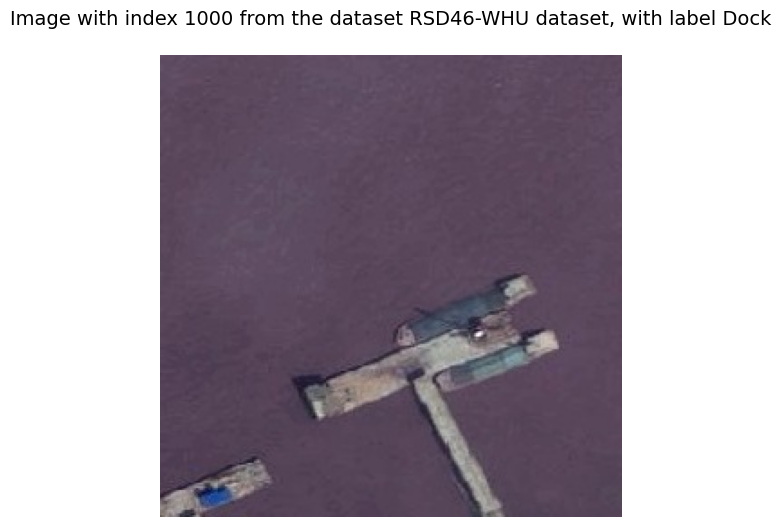

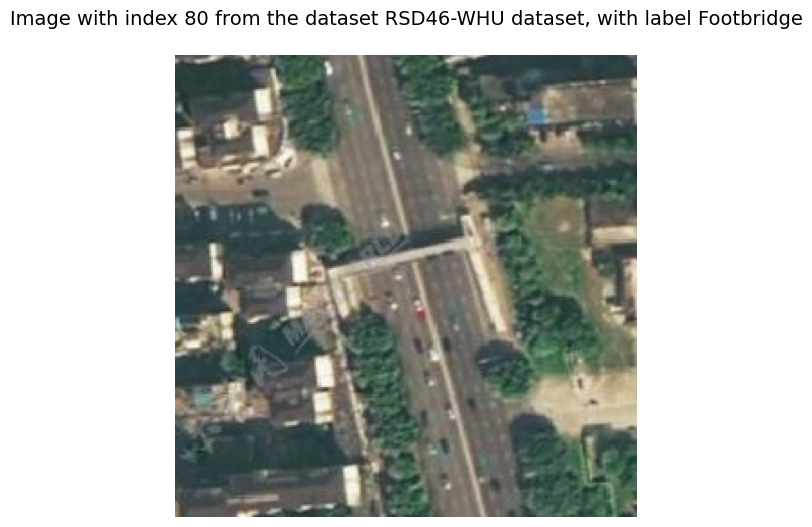

In [10]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

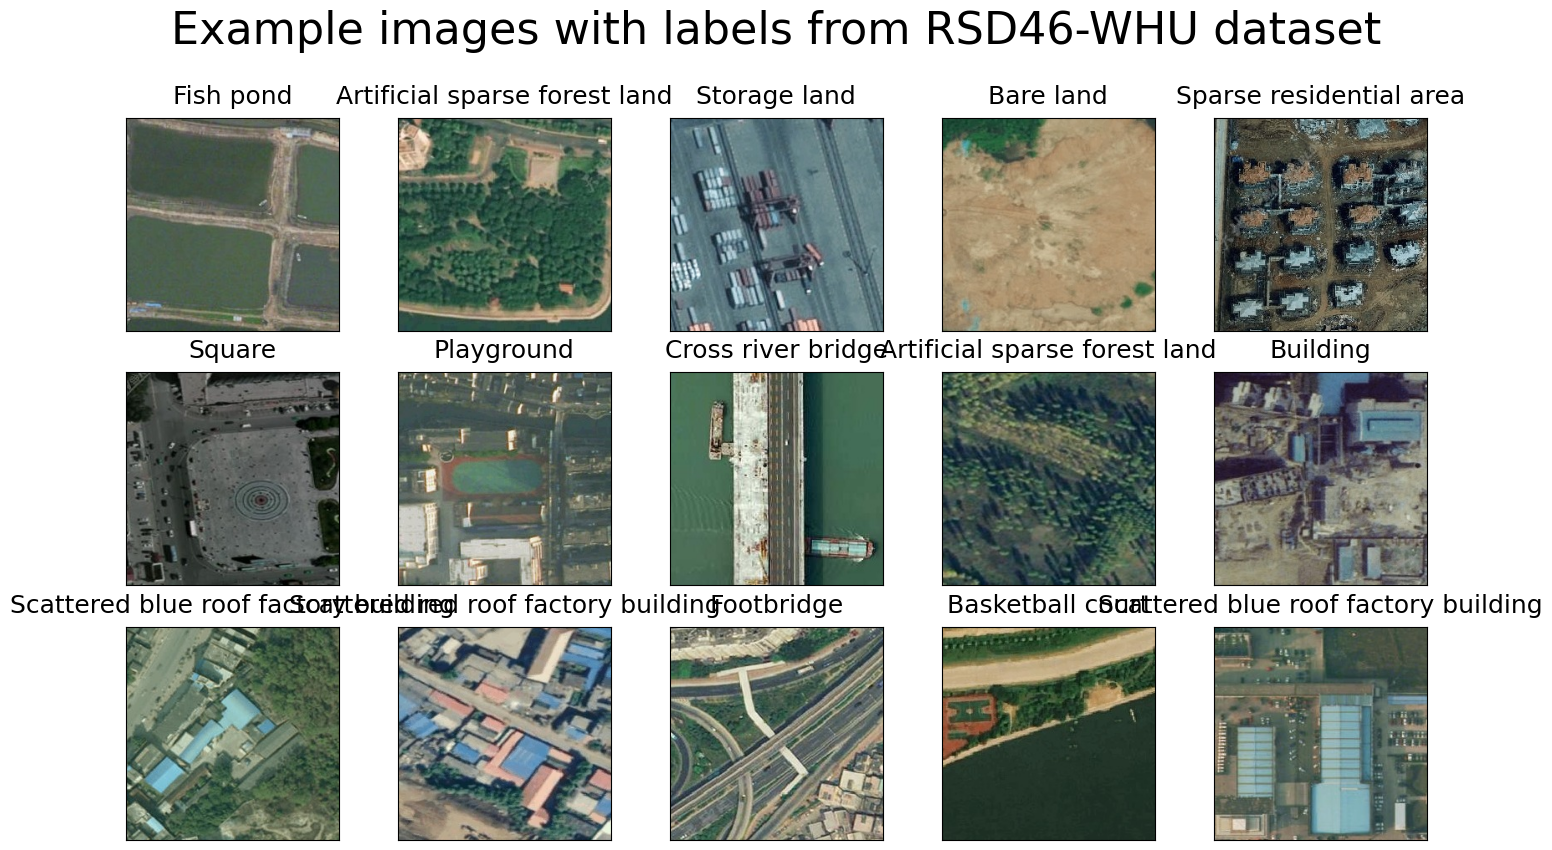

In [11]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [12]:
dataset.show_samples()

,File name,Label
0,Natural dense forest land/2016-08-28_154252.jpg,Natural dense forest land
1,Basketball court/ScreenShot12468.jpg,Basketball court
2,Basketball court/2016-08-28_215045.jpg,Basketball court
3,Artificial dense forest land/2016-09-01_165938...,Artificial dense forest land
4,Water/2016-08-01_152429.jpg,Water
5,Fish pond/ScreenShot10959.jpg,Fish pond
6,Low scattered building/ScreenShot07814.jpg,Low scattered building
7,Square/ScreenShot01148.jpg,Square
8,Red structured factory building/ScreenShot0664...,Red structured factory building
9,Thermal power plant/ScreenShot11451.jpg,Thermal power plant


In [13]:
dataset.data_distribution_table()

,Label,Count
0,Airplane,2060
1,Airport,1124
2,Artificial dense forest land,1910
3,Artificial sparse forest land,1923
4,Bare land,681
5,Basketball court,2027
6,Blue structured factory building,2089
7,Building,2352
8,Construction site,2229
9,Cross river bridge,1528


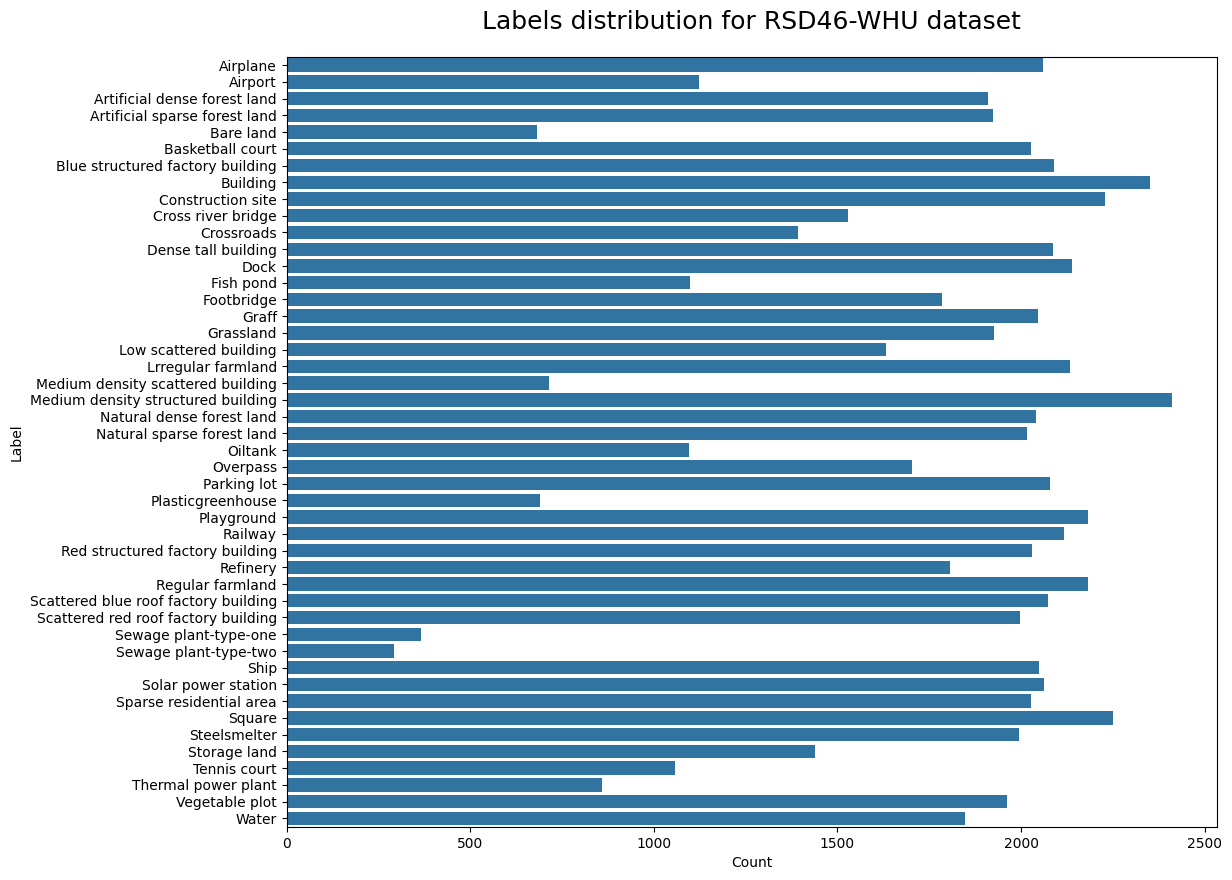

In [14]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/RSD46-WHU/train/",
    "csv_file": "./data/RSD46-WHU/rsd46whu_train.csv"
}

train_dataset = RSD46WHUDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/RSD46-WHU/test/",
    "csv_file": "./data/RSD46-WHU/rsd46whu_test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = RSD46WHUDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(79504, 17512)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/RSD46-WHU"
model_config = {
    "num_classes": 46,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [17]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 10:46:23,472 INFO Starting training.
training: 100%|██████████| 4969/4969 [05:20<00:00, 15.50it/s]
2026-08-24 10:51:44,253 INFO epoch: 1, time: 321, loss:  0.81565
testing on train set: 100%|██████████| 4969/4969 [02:20<00:00, 35.38it/s]
2026-08-24 10:54:05,437 INFO Accuracy:0.8597177500503119, Precision Micro:0.8597177500503119, Precision Macro:0.8709007651053283, Precision Weighted:0.8730825456983113, Precision per Class:[0.95646001 0.8986711  0.68594646 0.80699638 0.81419355 0.81720909
 0.96260069 0.68534799 0.84691196 0.98863636 0.98536942 0.60593091
 0.98220827 0.87055016 0.99393572 0.84510251 0.88612717 0.92926829
 0.96173212 0.52554745 0.91290111 0.72062868 0.91812865 0.82680251
 0.96068376 0.76855394 0.98278336 0.98122867 0.98289269 0.9860583
 0.72151899 0.90335114 0.74046649 0.74959416 0.74485597 0.93491124
 0.92769441 0.94387755 0.8391182  0.95585106 0.91538974 0.9800885
 0.94994675 0.88904694 0.80322004 0.97309674], Recall Micro:0.8597177500503119, Recall Macro:0.

0.1924491451434588

## Predictions

2026-08-24 12:33:09,135 INFO Loading checkpoint /home/dragik/data/experiments/RSD46-WHU/checkpoint.pth.tar
2026-08-24 12:33:09,763 INFO Loaded checkpoint /home/dragik/data/experiments/RSD46-WHU/checkpoint.pth.tar at epoch 11


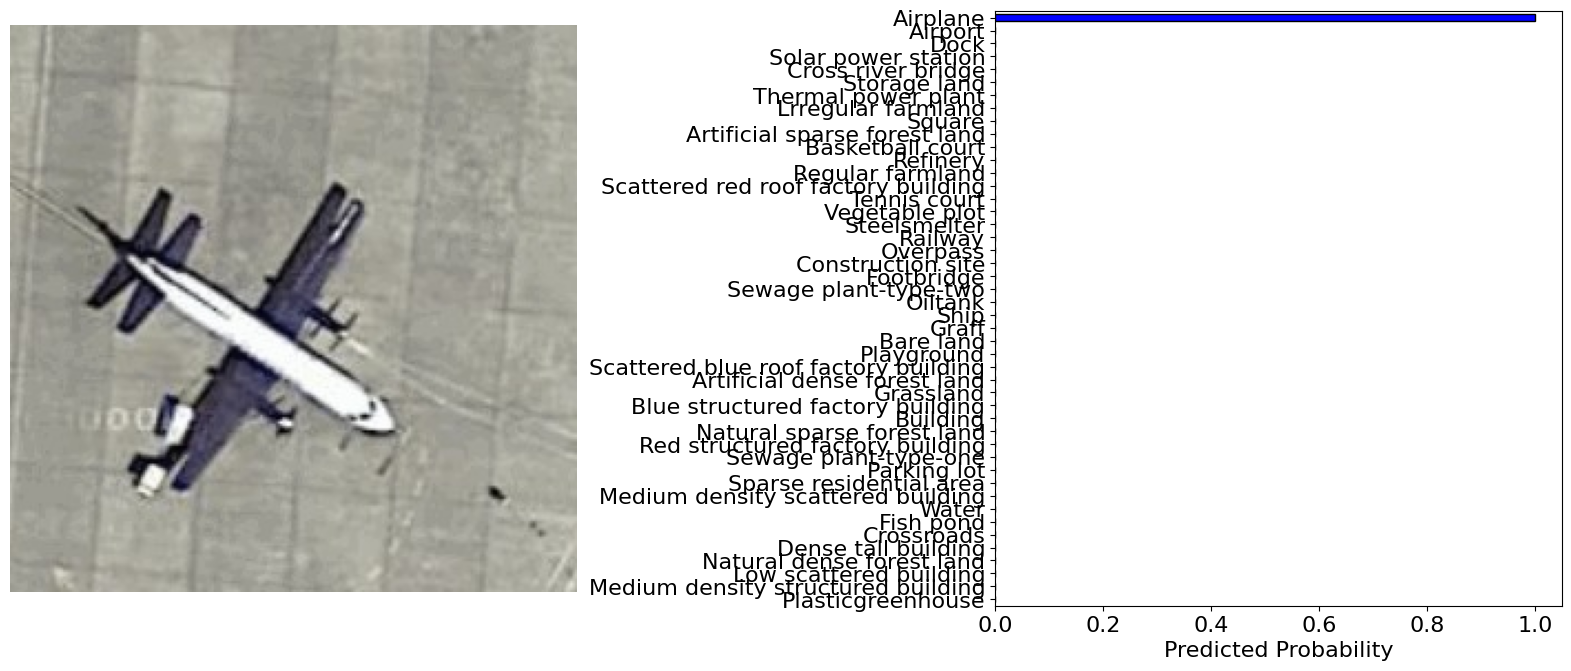

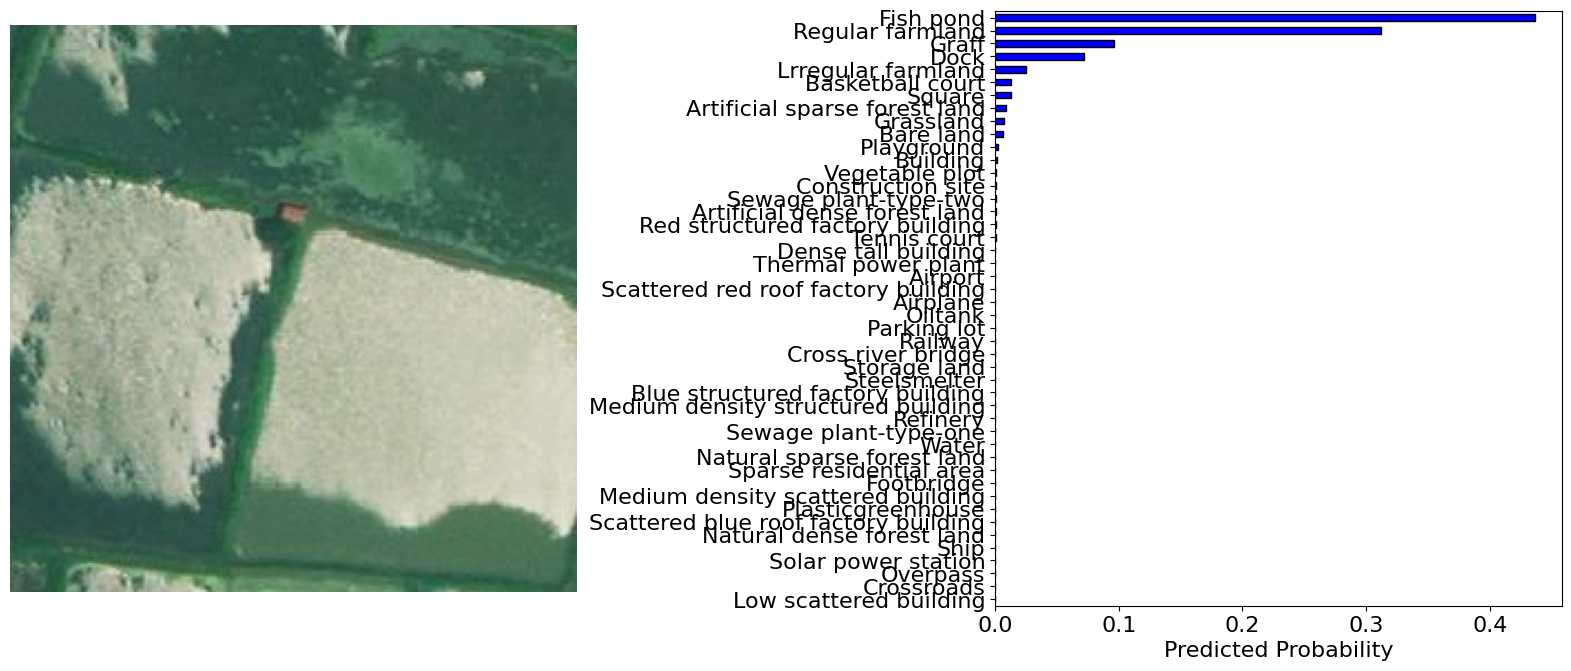

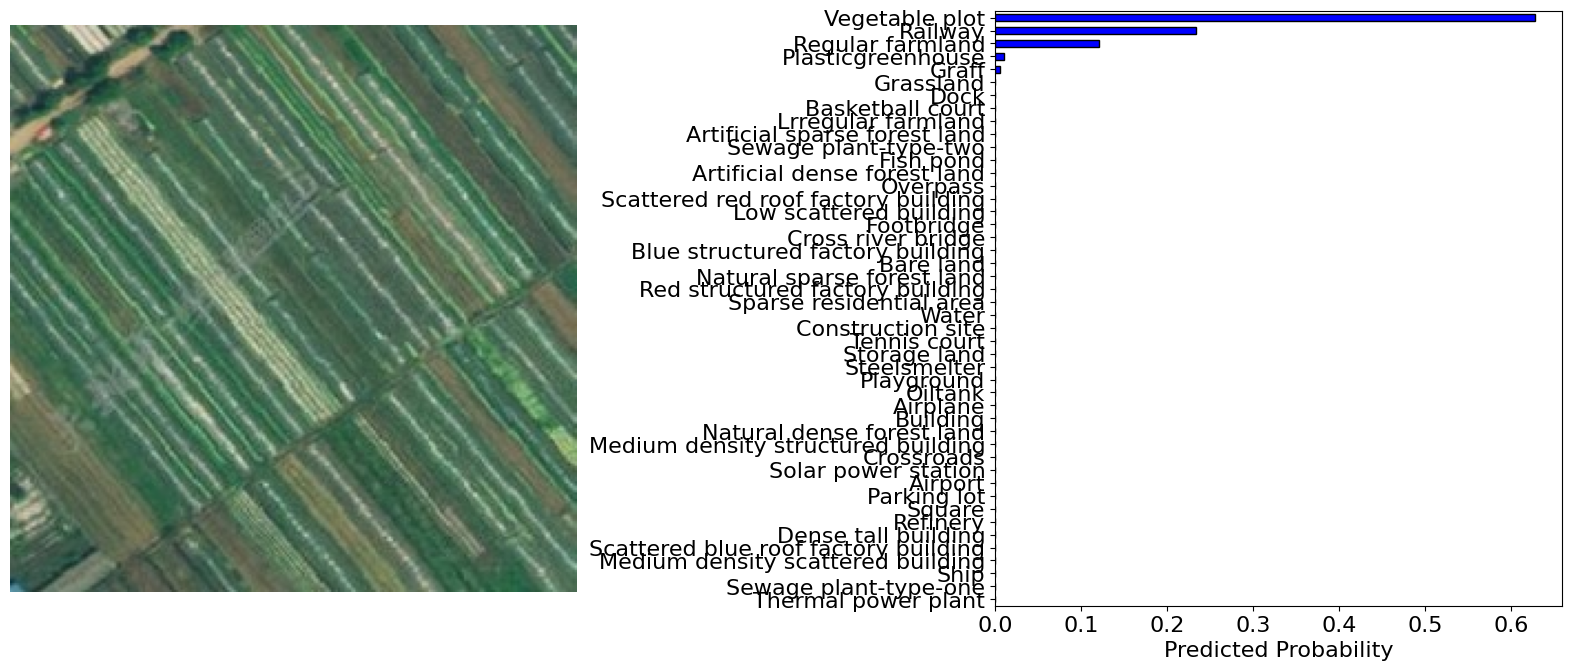

In [ ]:
model_path = "./data/experiments/RSD46-WHU/checkpoint.pth.tar"
labels = [
    "Airplane",
    "Airport",
    "Artificial dense forest land",
    "Artificial sparse forest land",
    "Bare land",
    "Basketball court",
    "Blue structured factory building",
    "Building",
    "Construction site",
    "Cross river bridge",
    "Crossroads",
    "Dense tall building",
    "Dock",
    "Fish pond",
    "Footbridge",
    "Graff",
    "Grassland",
    "Low scattered building",
    "Lrregular farmland",
    "Medium density scattered building",
    "Medium density structured building",
    "Natural dense forest land",
    "Natural sparse forest land",
    "Oiltank",
    "Overpass",
    "Parking lot",
    "Plasticgreenhouse",
    "Playground",
    "Railway",
    "Red structured factory building",
    "Refinery",
    "Regular farmland",
    "Scattered blue roof factory building",
    "Scattered red roof factory building",
    "Sewage plant-type-one",
    "Sewage plant-type-two",
    "Ship",
    "Solar power station",
    "Sparse residential area",
    "Square",
    "Steelsmelter",
    "Storage land",
    "Tennis court",
    "Thermal power plant",
    "Vegetable plot",
    "Water",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader("./data/RSD46-WHU/test/Airplane/2016-07-31_182817.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/RSD46-WHU/test/Fish pond/2016-09-25_185217.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/RSD46-WHU/test/Regular farmland/Administrator_2016-08-05_103028.jpg")
fig = model.predict_image(image, labels, transform)